## Overlay GCAM polygons and agricultural land
1. Read in GCAM polygon and crop land data
2. get cropland fractions by region
3. save result

In [32]:
import os

from affine import Affine
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio.features
import xarray as xr

# --- where to save final zarr
savehere = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/cropland+gcamRegions/'

### Read in GCAM polygons
From this [Zenodo deposit](https://zenodo.org/records/4688451#.YdMNTmjMJPY)

In [33]:
# --- read in data
datdir = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/gcam_boundaries_moirai_3p1_0p5arcmin_wgs84/main_outputs/'
fn = "region_boundaries_moirai_landcells_3p1_0p5arcmin.shp"
gdf = gpd.read_file(os.path.join(datdir, fn))

### Read in cropland data
From this [Zenodo deposit](https://zenodo.org/records/15363700)

In [56]:
import rioxarray as rxr

# --- read in data
datdir = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/Global agricultural lands in the year 2015 - dataset/'
fn = 'output_3_cropland.tif'
da = rxr.open_rasterio(os.path.join(datdir, fn))
# convert to xr dataset
da = da.squeeze("band", drop=True)
ds0 = da.to_dataset(name='cropland_frac')
# set NA value to zero
ds0['cropland_frac'] = ds0["cropland_frac"].where(ds0["cropland_frac"] <= 10, 0)
# coarsen to 1 degree
coarsen_deg = 1   # [INT, deg per coarsened cell]
ds = (
    ds0
    .coarsen(x=coarsen_deg*12, y=coarsen_deg*12, boundary="trim")  # (currently 1/12 degree)
    .mean()
)

In [57]:
# --- calculate cell areas
# earth radius (meters)
R = 6_371_000
# grid spacing in degrees
dlat = coarsen_deg
dlon = coarsen_deg
# convert to radians
dlat_rad = np.deg2rad(dlat)
dlon_rad = np.deg2rad(dlon)
# latitude centers
lat = ds["y"]
# compute latitude bounds
lat_rad = np.deg2rad(lat)
lat1 = lat_rad - dlat_rad / 2
lat2 = lat_rad + dlat_rad / 2
# area per latitude band (1D)
area_lat = R**2 * dlon_rad * (np.sin(lat2) - np.sin(lat1))
# broadcast to 2D
area = xr.DataArray(
    area_lat,
    coords={"y": ds["y"]},
    dims=["y"],
).broadcast_like(ds["cropland_frac"])
# add to dataset
ds["cell_area_m"] = area

### Add GCAM regional IDs to cropland data

In [58]:
# --- align crs
gdf = gdf.to_crs(ds.rio.crs)

# get pixel size
dx = float(ds.x[1] - ds.x[0])
dy = float(ds.y[0] - ds.y[1])  # negative because y decreases

# upper-left corner of top-left pixel
xmin = float(ds.x.min() - dx/2)
ymax = float(ds.y.max() + dy/2)

# affine transform
transform = Affine.translation(xmin, ymax) * Affine.scale(dx, -dy)

# shapes generator
shapes = ((geom, value) for geom, value in zip(gdf.geometry, gdf["reg_id"]))

# rasterize
region_array = rasterio.features.rasterize(
    shapes=shapes,
    out_shape=(ds.sizes["y"], ds.sizes["x"]),
    transform=transform,
    fill=0,
    dtype="int32",
    all_touched=False,
)

# assign to dataset
ds["reg_id"] = xr.DataArray(
    region_array,
    coords={"y": ds.y, "x": ds.x},
    dims=("y", "x"),
)

### Compute regional cropland fraction per pixel

In [59]:
# --- first get cropland area
ds['cropland_area'] = ds["cropland_frac"] * ds["cell_area_m"]
# total cropland for each region
total_cropland_by_region = (
    ds['cropland_area']
    .where(ds["reg_id"] > 0)                 # ignore reg_id=0
    .groupby(ds["reg_id"])
    .sum()
    .to_series()                                 # convert to pandas Series
)
# map back to pixels with reg_id
total_cropland_pixel = xr.DataArray(
    ds["reg_id"].values,                    # original grid
    coords={"y": ds.y, "x": ds.x},
    dims=("y", "x")
).astype(int)   
# vectorized lookup
total_cropland_pixel = np.vectorize(lambda rid: total_cropland_by_region.get(rid, np.nan))(total_cropland_pixel)
# back to ds
ds['cropland_area_by_region'] = xr.DataArray(
    total_cropland_pixel,
    coords={"y": ds.y, "x": ds.x},
    dims=("y", "x")
)

# --- fraction of regional cropland per pixel
ds["frac_regional_cropland"] = ds['cropland_area'] / ds['cropland_area_by_region']

### Save 

In [60]:
# --- save to zarr
fn = f'ds_cropland+gcam_{coarsen_deg}deg.zarr'
ds.to_zarr(os.path.join(savehere, fn))

/Users/tylerkukla/Documents/GitHub/ew-workflows/.venv/lib/python3.13/site-packages/zarr/api/asynchronous.py:244: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


### quick plots

In [61]:
fn_in = 's3://carbonplan-carbon-removal/ew-workflows-data/gcam/cropland+gcamRegions/ds_cropland+gcam_1deg.zarr/'
ds = xr.open_zarr(fn_in)

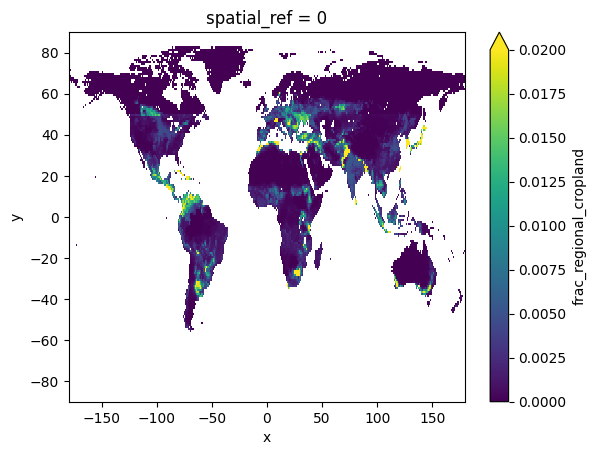

In [63]:
ds['frac_regional_cropland'].plot(vmin=0, vmax=0.02)

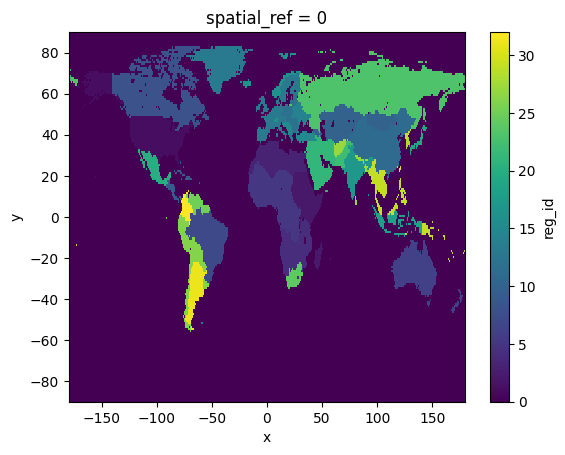

In [42]:
ds['reg_id'].plot()